In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Sales Data Filter & Report Engine")
print("Setup successful!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("All libraries are ready.")


Sales Data Filter & Report Engine
Setup successful!
Pandas version: 2.2.3
NumPy version: 2.1.3
All libraries are ready.


In [2]:

import pandas as pd

sales_data = {
    "Date": [
        "2026-10-01", "2026-10-01", "2026-10-02",
        "2026-10-02", "2026-10-03", "2026-10-03",
        "2026-10-04", "2026-10-04", "2026-10-05",
        "2026-10-05"
    ],
    "Product": [
        "Laptop", "Mouse", "Keyboard", "Laptop", "Monitor",
        "Mouse", "Keyboard", "Laptop", "Monitor", "Mouse"
    ],
    "Category": [
        "Electronics", "Accessories", "Accessories", "Electronics",
        "Electronics", "Accessories", "Accessories", "Electronics",
        "Electronics", "Accessories"
    ],
    "Quantity": [2, 5, 3, 1, 2, 4, 6, 1, 3, 2],
    "Price": [50000, 500, 1500, 50000, 12000, 500, 1500, 50000, 12000, 500],
    "City": [
        "Pune", "Mumbai", "Delhi", "Pune", "Mumbai",
        "Delhi", "Pune", "Delhi", "Pune", "Mumbai"
    ]
}

df = pd.DataFrame(sales_data)

print("Dataset created successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df)


Dataset created successfully!
Number of rows: 10
Number of columns: 6


,Date,Product,Category,Quantity,Price,City
0,2026-10-01,Laptop,Electronics,2,50000,Pune
1,2026-10-01,Mouse,Accessories,5,500,Mumbai
2,2026-10-02,Keyboard,Accessories,3,1500,Delhi
3,2026-10-02,Laptop,Electronics,1,50000,Pune
4,2026-10-03,Monitor,Electronics,2,12000,Mumbai
5,2026-10-03,Mouse,Accessories,4,500,Delhi
6,2026-10-04,Keyboard,Accessories,6,1500,Pune
7,2026-10-04,Laptop,Electronics,1,50000,Delhi
8,2026-10-05,Monitor,Electronics,3,12000,Pune
9,2026-10-05,Mouse,Accessories,2,500,Mumbai


In [3]:

# Calculate total sales for each order
df["Total_Sales"] = df["Quantity"] * df["Price"]

print("Total sales calculated successfully!")

# Display the updated dataset
display(df)


Total sales calculated successfully!


,Date,Product,Category,Quantity,Price,City,Total_Sales
0,2026-10-01,Laptop,Electronics,2,50000,Pune,100000
1,2026-10-01,Mouse,Accessories,5,500,Mumbai,2500
2,2026-10-02,Keyboard,Accessories,3,1500,Delhi,4500
3,2026-10-02,Laptop,Electronics,1,50000,Pune,50000
4,2026-10-03,Monitor,Electronics,2,12000,Mumbai,24000
5,2026-10-03,Mouse,Accessories,4,500,Delhi,2000
6,2026-10-04,Keyboard,Accessories,6,1500,Pune,9000
7,2026-10-04,Laptop,Electronics,1,50000,Delhi,50000
8,2026-10-05,Monitor,Electronics,3,12000,Pune,36000
9,2026-10-05,Mouse,Accessories,2,500,Mumbai,1000


In [4]:

total_revenue = df["Total_Sales"].sum()
total_orders = len(df)
average_order_value = df["Total_Sales"].mean()

print("===== SALES SUMMARY REPORT =====")
print("Total Revenue: Rs.", total_revenue)
print("Total Orders:", total_orders)
print("Average Order Value: Rs.", average_order_value)


===== SALES SUMMARY REPORT =====
Total Revenue: Rs. 279000
Total Orders: 10
Average Order Value: Rs. 27900.0


===== PRODUCT-WISE SALES =====


,Product,Total_Sales
0,Keyboard,13500
1,Laptop,200000
2,Monitor,60000
3,Mouse,5500


Top Product by Revenue: Laptop
Total Sales of Top Product: Rs. 200000


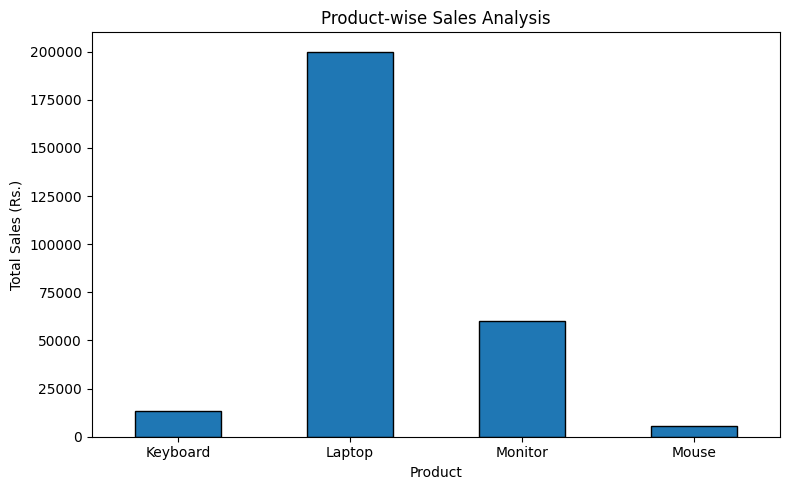

In [5]:

# Calculate total sales for each product
product_sales = df.groupby("Product")["Total_Sales"].sum()

# Display product-wise sales
print("===== PRODUCT-WISE SALES =====")
display(product_sales.reset_index())

# Find the best-selling product by revenue
best_product = product_sales.idxmax()
best_revenue = product_sales.max()

print("Top Product by Revenue:", best_product)
print("Total Sales of Top Product: Rs.", best_revenue)

# Create a bar chart
product_sales.plot(kind="bar", figsize=(8, 5), edgecolor="black")

plt.title("Product-wise Sales Analysis")
plt.xlabel("Product")
plt.ylabel("Total Sales (Rs.)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [6]:

# Calculate total sales for each city
city_sales = df.groupby("City")["Total_Sales"].sum()

print("===== CITY-WISE SALES REPORT =====")
display(city_sales.reset_index())

# Find the city with the highest revenue
top_city = city_sales.idxmax()
top_city_sales = city_sales.max()

print("Top City:", top_city)
print("Top City Sales: Rs.", top_city_sales)


===== CITY-WISE SALES REPORT =====


,City,Total_Sales
0,Delhi,56500
1,Mumbai,27500
2,Pune,195000


Top City: Pune
Top City Sales: Rs. 195000


In [7]:

# Filter sales records for Pune
selected_city = "Pune"

filtered_data = df[df["City"] == selected_city]

print("===== FILTERED SALES DATA =====")
print("Selected City:", selected_city)
display(filtered_data)

print("Total Sales in", selected_city, ": Rs.",
      filtered_data["Total_Sales"].sum())


===== FILTERED SALES DATA =====
Selected City: Pune


,Date,Product,Category,Quantity,Price,City,Total_Sales
0,2026-10-01,Laptop,Electronics,2,50000,Pune,100000
3,2026-10-02,Laptop,Electronics,1,50000,Pune,50000
6,2026-10-04,Keyboard,Accessories,6,1500,Pune,9000
8,2026-10-05,Monitor,Electronics,3,12000,Pune,36000


Total Sales in Pune : Rs. 195000


In [8]:

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Select a date to analyze
selected_date = "2026-10-03"

filtered_date_data = df[
    df["Date"] == pd.to_datetime(selected_date)
]

print("===== DATE-WISE SALES REPORT =====")
print("Selected Date:", selected_date)
display(filtered_date_data)

date_revenue = filtered_date_data["Total_Sales"].sum()
date_orders = len(filtered_date_data)

print("Total Orders:", date_orders)
print("Total Sales: Rs.", date_revenue)


===== DATE-WISE SALES REPORT =====
Selected Date: 2026-10-03


,Date,Product,Category,Quantity,Price,City,Total_Sales
4,2026-10-03,Monitor,Electronics,2,12000,Mumbai,24000
5,2026-10-03,Mouse,Accessories,4,500,Delhi,2000


Total Orders: 2
Total Sales: Rs. 26000


===== CATEGORY-WISE SALES REPORT =====


,Category,Total_Sales
0,Accessories,19000
1,Electronics,260000


Top Category: Electronics
Category Revenue: Rs. 260000


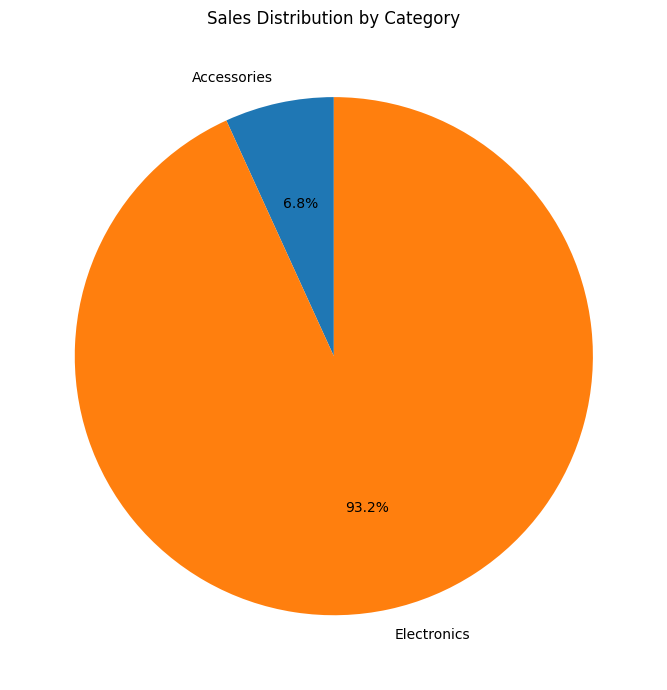

In [9]:

# Calculate sales by product category
category_sales = df.groupby("Category")["Total_Sales"].sum()

print("===== CATEGORY-WISE SALES REPORT =====")
display(category_sales.reset_index())

# Find the highest-revenue category
top_category = category_sales.idxmax()
top_category_revenue = category_sales.max()

print("Top Category:", top_category)
print("Category Revenue: Rs.", top_category_revenue)

# Create a pie chart
category_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    startangle=90
)

plt.title("Sales Distribution by Category")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [10]:

def filter_sales(data, product=None, city=None, category=None):
    filtered = data.copy()

    if product is not None:
        filtered = filtered[filtered["Product"] == product]

    if city is not None:
        filtered = filtered[filtered["City"] == city]

    if category is not None:
        filtered = filtered[filtered["Category"] == category]

    return filtered


# Example: Filter sales from Pune
result = filter_sales(df, city="Pune")

print("===== REUSABLE SALES FILTER =====")
print("Selected City: Pune")
print("Matching Records:", len(result))
display(result)

print("Filtered Revenue: Rs.", result["Total_Sales"].sum())


===== REUSABLE SALES FILTER =====
Selected City: Pune
Matching Records: 4


,Date,Product,Category,Quantity,Price,City,Total_Sales
0,2026-10-01,Laptop,Electronics,2,50000,Pune,100000
3,2026-10-02,Laptop,Electronics,1,50000,Pune,50000
6,2026-10-04,Keyboard,Accessories,6,1500,Pune,9000
8,2026-10-05,Monitor,Electronics,3,12000,Pune,36000


Filtered Revenue: Rs. 195000


In [11]:

# Test 1: Find all Laptop sales
laptop_sales = filter_sales(df, product="Laptop")
print("Laptop records:", len(laptop_sales))
print("Laptop revenue: Rs.", laptop_sales["Total_Sales"].sum())

# Test 2: Find Electronics sales in Pune
pune_electronics = filter_sales(
    df,
    city="Pune",
    category="Electronics"
)
print("Pune Electronics records:", len(pune_electronics))
print("Pune Electronics revenue: Rs.",
      pune_electronics["Total_Sales"].sum())


Laptop records: 3
Laptop revenue: Rs. 200000
Pune Electronics records: 3
Pune Electronics revenue: Rs. 186000


In [12]:
# Export Pune sales report to a CSV file
result.to_csv("pune_sales_report.csv", index=False)

print("Report exported successfully!")
print("File name: pune_sales_report.csv")


Report exported successfully!
File name: pune_sales_report.csv


In [13]:
from google.colab import files

files.download("pune_sales_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
def filter_by_date_range(data, start_date, end_date):
    start_date = pd.to_datetime(start_date)
    end_date = pd.to_datetime(end_date)

    filtered = data[
        (data["Date"] >= start_date) &
        (data["Date"] <= end_date)
    ]

    return filtered


# Example: Sales from October 2 to October 4
date_range_report = filter_by_date_range(
    df,
    "2026-10-02",
    "2026-10-04"
)

print("===== DATE RANGE SALES REPORT =====")
print("Start Date: 2026-10-02")
print("End Date: 2026-10-04")
print("Total Orders:", len(date_range_report))

display(date_range_report)

print(
    "Total Revenue: Rs.",
    date_range_report["Total_Sales"].sum()
)

===== DATE RANGE SALES REPORT =====
Start Date: 2026-10-02
End Date: 2026-10-04
Total Orders: 6


,Date,Product,Category,Quantity,Price,City,Total_Sales
2,2026-10-02,Keyboard,Accessories,3,1500,Delhi,4500
3,2026-10-02,Laptop,Electronics,1,50000,Pune,50000
4,2026-10-03,Monitor,Electronics,2,12000,Mumbai,24000
5,2026-10-03,Mouse,Accessories,4,500,Delhi,2000
6,2026-10-04,Keyboard,Accessories,6,1500,Pune,9000
7,2026-10-04,Laptop,Electronics,1,50000,Delhi,50000


Total Revenue: Rs. 139500


In [15]:
def generate_sales_report(data):
    print("===== SALES SUMMARY REPORT =====")

    if data.empty:
        print("No sales records found.")
        return

    total_revenue = data["Total_Sales"].sum()
    total_orders = len(data)
    average_order_value = data["Total_Sales"].mean()

    product_sales = data.groupby("Product")["Total_Sales"].sum()
    top_product = product_sales.idxmax()

    print("Total Revenue: Rs.", total_revenue)
    print("Total Orders:", total_orders)
    print("Average Order Value: Rs.", round(average_order_value, 2))
    print("Top Product:", top_product)


# Generate report for the full dataset
generate_sales_report(df)

===== SALES SUMMARY REPORT =====
Total Revenue: Rs. 279000
Total Orders: 10
Average Order Value: Rs. 27900.0
Top Product: Laptop


In [16]:
# Find the 5 records with the highest sales
top_5_sales = df.nlargest(5, "Total_Sales")

print("===== TOP 5 SALES RECORDS =====")

display(
    top_5_sales[
        ["Date", "Product", "City", "Quantity", "Total_Sales"]
    ]
)

===== TOP 5 SALES RECORDS =====


,Date,Product,City,Quantity,Total_Sales
0,2026-10-01,Laptop,Pune,2,100000
3,2026-10-02,Laptop,Pune,1,50000
7,2026-10-04,Laptop,Delhi,1,50000
8,2026-10-05,Monitor,Pune,3,36000
4,2026-10-03,Monitor,Mumbai,2,24000
